# Import models 

In [1]:
import os
import subprocess
import pandas as pd
import numpy as np
import optuna
from optuna.samplers import NSGAIIISampler
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import re

C:\Users\hp\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Simulator running script

In [2]:
# =========================
# PATHS
# =========================
ECLRUN_EXE = r"C:\ecl\macros\eclrun.exe"
BASE_DIR = r"C:\Users\hp\Desktop\Eclipsetimesteps"

DATA_FILE_NAME = "Egg_Model_ECL.DATA"
RSM_FILE_NAME = "Egg_Model_ECL.RSM"
RSM_PATH = os.path.join(BASE_DIR, "EGG_MODEL_ECL.RSM")

N_BLOCKS = 5
BLOCK_END_DAYS = 720  # end of each block (24*30)
TARGET_TIMES = [BLOCK_END_DAYS * i for i in range(1, N_BLOCKS + 1)]
FINAL_TIME = TARGET_TIMES[-1]

In [3]:
# =========================
# RUN ECLIPSE
# =========================
def run_eclipse():
    print("▶ Running Eclipse ...")
    cmd = [ECLRUN_EXE, "eclipse", DATA_FILE_NAME]
    subprocess.run(cmd, cwd=BASE_DIR, check=True)
    print("✔ Eclipse finished")

# =========================
# EXTRACT FOPT & FWPT PER BLOCK
# =========================
def extract_FOPT_FWPT_from_RSM(rsm_path):

    with open(rsm_path, "r") as f:
        lines = f.readlines()

    inside_summary = False
    fopt_idx = fwpt_idx = None

    for line in lines:

        if "SUMMARY OF RUN" in line:
            inside_summary = True
            fopt_idx = fwpt_idx = None
            continue

        if not inside_summary:
            continue

        tokens = line.split()
        if not tokens:
            continue

        # Detect column headers
        if fopt_idx is None and "FOPT" in tokens and "FWPT" in tokens:
            fopt_idx = tokens.index("FOPT")
            fwpt_idx = tokens.index("FWPT")
            continue

        if fopt_idx is None:
            continue

        # ✅ Only data rows have numeric TIME
        if not tokens[0][0].isdigit():
            continue
        if float(tokens[0]) == 3600.0:
            return float(tokens[fopt_idx]), float(tokens[fwpt_idx])

In [4]:
def modify_data_per_control_block(blocks_params):

    data_path = os.path.join(BASE_DIR, DATA_FILE_NAME)

    with open(data_path, "r") as f:
        lines = f.readlines()

    block_pattern = re.compile(r"--\s*Block\s+(\d+)", re.IGNORECASE)

    current_block = None
    new_lines = []

    for line in lines:

        # Detect block number
        m = block_pattern.search(line)
        if m:
            current_block = int(m.group(1))
            new_lines.append(line)
            continue

        # Skip if block not in params
        if current_block is None or current_block > len(blocks_params):
            new_lines.append(line)
            continue

        params = blocks_params[current_block - 1]
        stripped = line.strip()

        # -------------------------
        # PRODUCER BHP
        # -------------------------
        prod_match = re.match(r"'PROD(\d+)'", stripped)
        if prod_match and "'BHP'" in stripped:

            prod_num = prod_match.group(1)
            key = f"BHP{prod_num}"

            if key in params:
                bhp_value = int(params[key])

                # Replace last numeric value in line (robust)
                line = re.sub(r"(5\*\s*)(\d+)", rf"\g<1>{bhp_value}", line)

        # -------------------------
        # INJECTOR RATE
        # -------------------------
        inj_match = re.match(r"'INJECT(\d+)'", stripped)
        if inj_match and "'RATE'" in stripped:

            inj_num = inj_match.group(1)
            key = f"inj_rate{inj_num}"

            if key in params:
                rate_value = int(params[key])

                # Replace RATE value robustly
                line = re.sub(r"('RATE'\s+)(\d+)", rf"\g<1>{rate_value}", line)

        new_lines.append(line)

    with open(data_path, "w") as f:
        f.writelines(new_lines)

# Define objective optimization function

In [5]:
def objective(trial):

    # 1) Suggest parameters per control block
    blocks_params = []
    for b in range(1, N_BLOCKS + 1):
        blocks_params.append({
            "BHP1": trial.suggest_int(f"BHP1_b{b}", 150, 390),
            "BHP2": trial.suggest_int(f"BHP2_b{b}", 150, 390),
            "BHP3": trial.suggest_int(f"BHP3_b{b}", 150, 390),
            "BHP4": trial.suggest_int(f"BHP4_b{b}", 150, 390),
            "inj_rate1": trial.suggest_int(f"inj_rate1_b{b}", 50, 400),
            "inj_rate2": trial.suggest_int(f"inj_rate2_b{b}", 50, 400),
            "inj_rate3": trial.suggest_int(f"inj_rate3_b{b}", 50, 400),
            "inj_rate4": trial.suggest_int(f"inj_rate4_b{b}", 50, 400),
            "inj_rate5": trial.suggest_int(f"inj_rate5_b{b}", 50, 400),
            "inj_rate6": trial.suggest_int(f"inj_rate6_b{b}", 50, 400),
            "inj_rate7": trial.suggest_int(f"inj_rate7_b{b}", 50, 400),
            "inj_rate8": trial.suggest_int(f"inj_rate8_b{b}", 50, 400),
        })

    # 2) Update schedule per CONTROL BLOCK (BHP + RATE)
    modify_data_per_control_block(blocks_params)

    run_eclipse()
    # 3) Extract FOPT/FWPT at block end times
    fopt, fwpt = extract_FOPT_FWPT_from_RSM(RSM_PATH)
    return fopt, fwpt

# Optimization running 

In [6]:
sampler = optuna.samplers.TPESampler(
    n_startup_trials=42,
    multivariate=False,
    seed=42)

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=sampler,
    study_name="ECLIPSE_SUM_DELTA_FOPT_FWPT"
)

study.optimize(objective, n_trials=100, show_progress_bar=False)

[I 2026-11-08 20:11:29,842] A new study created in memory with name: ECLIPSE_SUM_DELTA_FOPT_FWPT


▶ Running Eclipse ...


[I 2026-11-08 20:12:41,208] Trial 0 finished with values: [543062.1, 5438268.0] and parameters: {'BHP1_b1': 240, 'BHP2_b1': 379, 'BHP3_b1': 326, 'BHP4_b1': 294, 'inj_rate1_b1': 104, 'inj_rate2_b1': 104, 'inj_rate3_b1': 70, 'inj_rate4_b1': 354, 'inj_rate5_b1': 260, 'inj_rate6_b1': 298, 'inj_rate7_b1': 57, 'inj_rate8_b1': 390, 'BHP1_b2': 350, 'BHP2_b2': 201, 'BHP3_b2': 193, 'BHP4_b2': 194, 'inj_rate1_b2': 156, 'inj_rate2_b2': 234, 'inj_rate3_b2': 201, 'inj_rate4_b2': 152, 'inj_rate5_b2': 264, 'inj_rate6_b2': 98, 'inj_rate7_b2': 152, 'inj_rate8_b2': 178, 'BHP1_b3': 259, 'BHP2_b3': 339, 'BHP3_b3': 198, 'BHP4_b3': 273, 'inj_rate1_b3': 257, 'inj_rate2_b3': 66, 'inj_rate3_b3': 263, 'inj_rate4_b3': 109, 'inj_rate5_b3': 72, 'inj_rate6_b3': 383, 'inj_rate7_b3': 388, 'inj_rate8_b3': 333, 'BHP1_b4': 223, 'BHP2_b4': 173, 'BHP3_b4': 314, 'BHP4_b4': 256, 'inj_rate1_b4': 92, 'inj_rate2_b4': 223, 'inj_rate3_b4': 62, 'inj_rate4_b4': 369, 'inj_rate5_b4': 140, 'inj_rate6_b4': 282, 'inj_rate7_b4': 159, 'in

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-08 20:13:49,534] Trial 1 finished with values: [547082.7, 6253821.0] and parameters: {'BHP1_b1': 243, 'BHP2_b1': 215, 'BHP3_b1': 349, 'BHP4_b1': 235, 'inj_rate1_b1': 148, 'inj_rate2_b1': 240, 'inj_rate3_b1': 99, 'inj_rate4_b1': 331, 'inj_rate5_b1': 76, 'inj_rate6_b1': 396, 'inj_rate7_b1': 321, 'inj_rate8_b1': 119, 'BHP1_b2': 151, 'BHP2_b2': 346, 'BHP3_b2': 320, 'BHP4_b2': 325, 'inj_rate1_b2': 320, 'inj_rate2_b2': 75, 'inj_rate3_b2': 175, 'inj_rate4_b2': 90, 'inj_rate5_b2': 352, 'inj_rate6_b2': 268, 'inj_rate7_b2': 166, 'inj_rate8_b2': 72, 'BHP1_b3': 224, 'BHP2_b3': 228, 'BHP3_b3': 325, 'BHP4_b3': 303, 'inj_rate1_b3': 361, 'inj_rate2_b3': 215, 'inj_rate3_b3': 91, 'inj_rate4_b3': 300, 'inj_rate5_b3': 317, 'inj_rate6_b3': 247, 'inj_rate7_b3': 320, 'inj_rate8_b3': 223, 'BHP1_b4': 275, 'BHP2_b4': 253, 'BHP3_b4': 156, 'BHP4_b4': 176, 'inj_rate1_b4': 61, 'inj_rate2_b4': 273, 'inj_rate3_b4': 160, 'inj_rate4_b4': 228, 'inj_rate5_b4': 368, 'inj_rate6_b4': 137, 'inj_rate7_b4': 194, 'in

✔ Eclipse finished
▶ Running Eclipse ...


... (192 outputs left out)

[I 2026-11-08 22:57:34,584] Trial 98 finished with values: [539784.8, 5253433.0] and parameters: {'BHP1_b1': 163, 'BHP2_b1': 248, 'BHP3_b1': 214, 'BHP4_b1': 266, 'inj_rate1_b1': 246, 'inj_rate2_b1': 306, 'inj_rate3_b1': 58, 'inj_rate4_b1': 383, 'inj_rate5_b1': 242, 'inj_rate6_b1': 231, 'inj_rate7_b1': 205, 'inj_rate8_b1': 115, 'BHP1_b2': 227, 'BHP2_b2': 172, 'BHP3_b2': 192, 'BHP4_b2': 245, 'inj_rate1_b2': 160, 'inj_rate2_b2': 72, 'inj_rate3_b2': 181, 'inj_rate4_b2': 229, 'inj_rate5_b2': 383, 'inj_rate6_b2': 116, 'inj_rate7_b2': 112, 'inj_rate8_b2': 116, 'BHP1_b3': 154, 'BHP2_b3': 303, 'BHP3_b3': 259, 'BHP4_b3': 289, 'inj_rate1_b3': 117, 'inj_rate2_b3': 271, 'inj_rate3_b3': 270, 'inj_rate4_b3': 149, 'inj_rate5_b3': 222, 'inj_rate6_b3': 380, 'inj_rate7_b3': 188, 'inj_rate8_b3': 153, 'BHP1_b4': 348, 'BHP2_b4': 376, 'BHP3_b4': 154, 'BHP4_b4': 366, 'inj_rate1_b4': 99, 'inj_rate2_b4': 222, 'inj_rate3_b4': 212, 'inj_rate4_b4': 214, 'inj_rate5_b4': 105, 'inj_rate6_b4': 113, 'inj_rate7_b4': 87,

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-08 23:00:05,493] Trial 99 finished with values: [537120.1, 4106701.0] and parameters: {'BHP1_b1': 150, 'BHP2_b1': 177, 'BHP3_b1': 374, 'BHP4_b1': 167, 'inj_rate1_b1': 289, 'inj_rate2_b1': 105, 'inj_rate3_b1': 220, 'inj_rate4_b1': 132, 'inj_rate5_b1': 57, 'inj_rate6_b1': 96, 'inj_rate7_b1': 142, 'inj_rate8_b1': 273, 'BHP1_b2': 246, 'BHP2_b2': 179, 'BHP3_b2': 282, 'BHP4_b2': 273, 'inj_rate1_b2': 80, 'inj_rate2_b2': 278, 'inj_rate3_b2': 327, 'inj_rate4_b2': 382, 'inj_rate5_b2': 50, 'inj_rate6_b2': 398, 'inj_rate7_b2': 178, 'inj_rate8_b2': 133, 'BHP1_b3': 371, 'BHP2_b3': 254, 'BHP3_b3': 379, 'BHP4_b3': 352, 'inj_rate1_b3': 217, 'inj_rate2_b3': 133, 'inj_rate3_b3': 284, 'inj_rate4_b3': 223, 'inj_rate5_b3': 379, 'inj_rate6_b3': 146, 'inj_rate7_b3': 56, 'inj_rate8_b3': 267, 'BHP1_b4': 284, 'BHP2_b4': 359, 'BHP3_b4': 168, 'BHP4_b4': 208, 'inj_rate1_b4': 176, 'inj_rate2_b4': 334, 'inj_rate3_b4': 334, 'inj_rate4_b4': 186, 'inj_rate5_b4': 194, 'inj_rate6_b4': 99, 'inj_rate7_b4': 68, 'i

✔ Eclipse finished


In [7]:
pareto = study.best_trials  # Pareto front

for i, t in enumerate(pareto[:10], start=1):
    print(f"\n--- Pareto solution {i} ---")
    print("ΣΔFOPT:", t.values[0], " ΣΔFWPT:", t.values[1])
    # print some parameters
    for k in sorted(t.params.keys()):
        print(k, "=", t.params[k])


--- Pareto solution 1 ---
ΣΔFOPT: 540790.1  ΣΔFWPT: 4639049.0
BHP1_b1 = 340
BHP1_b2 = 298
BHP1_b3 = 345
BHP1_b4 = 152
BHP1_b5 = 203
BHP2_b1 = 340
BHP2_b2 = 174
BHP2_b3 = 378
BHP2_b4 = 262
BHP2_b5 = 382
BHP3_b1 = 171
BHP3_b2 = 170
BHP3_b3 = 387
BHP3_b4 = 163
BHP3_b5 = 152
BHP4_b1 = 269
BHP4_b2 = 318
BHP4_b3 = 331
BHP4_b4 = 178
BHP4_b5 = 383
inj_rate1_b1 = 70
inj_rate1_b2 = 75
inj_rate1_b3 = 182
inj_rate1_b4 = 91
inj_rate1_b5 = 65
inj_rate2_b1 = 242
inj_rate2_b2 = 338
inj_rate2_b3 = 79
inj_rate2_b4 = 277
inj_rate2_b5 = 362
inj_rate3_b1 = 204
inj_rate3_b2 = 297
inj_rate3_b3 = 322
inj_rate3_b4 = 311
inj_rate3_b5 = 235
inj_rate4_b1 = 361
inj_rate4_b2 = 78
inj_rate4_b3 = 245
inj_rate4_b4 = 254
inj_rate4_b5 = 398
inj_rate5_b1 = 173
inj_rate5_b2 = 79
inj_rate5_b3 = 198
inj_rate5_b4 = 387
inj_rate5_b5 = 75
inj_rate6_b1 = 91
inj_rate6_b2 = 396
inj_rate6_b3 = 368
inj_rate6_b4 = 181
inj_rate6_b5 = 244
inj_rate7_b1 = 100
inj_rate7_b2 = 181
inj_rate7_b3 = 89
inj_rate7_b4 = 150
inj_rate7_b5 = 390
in

# The plot of FOPT & FWPT  for the base case:

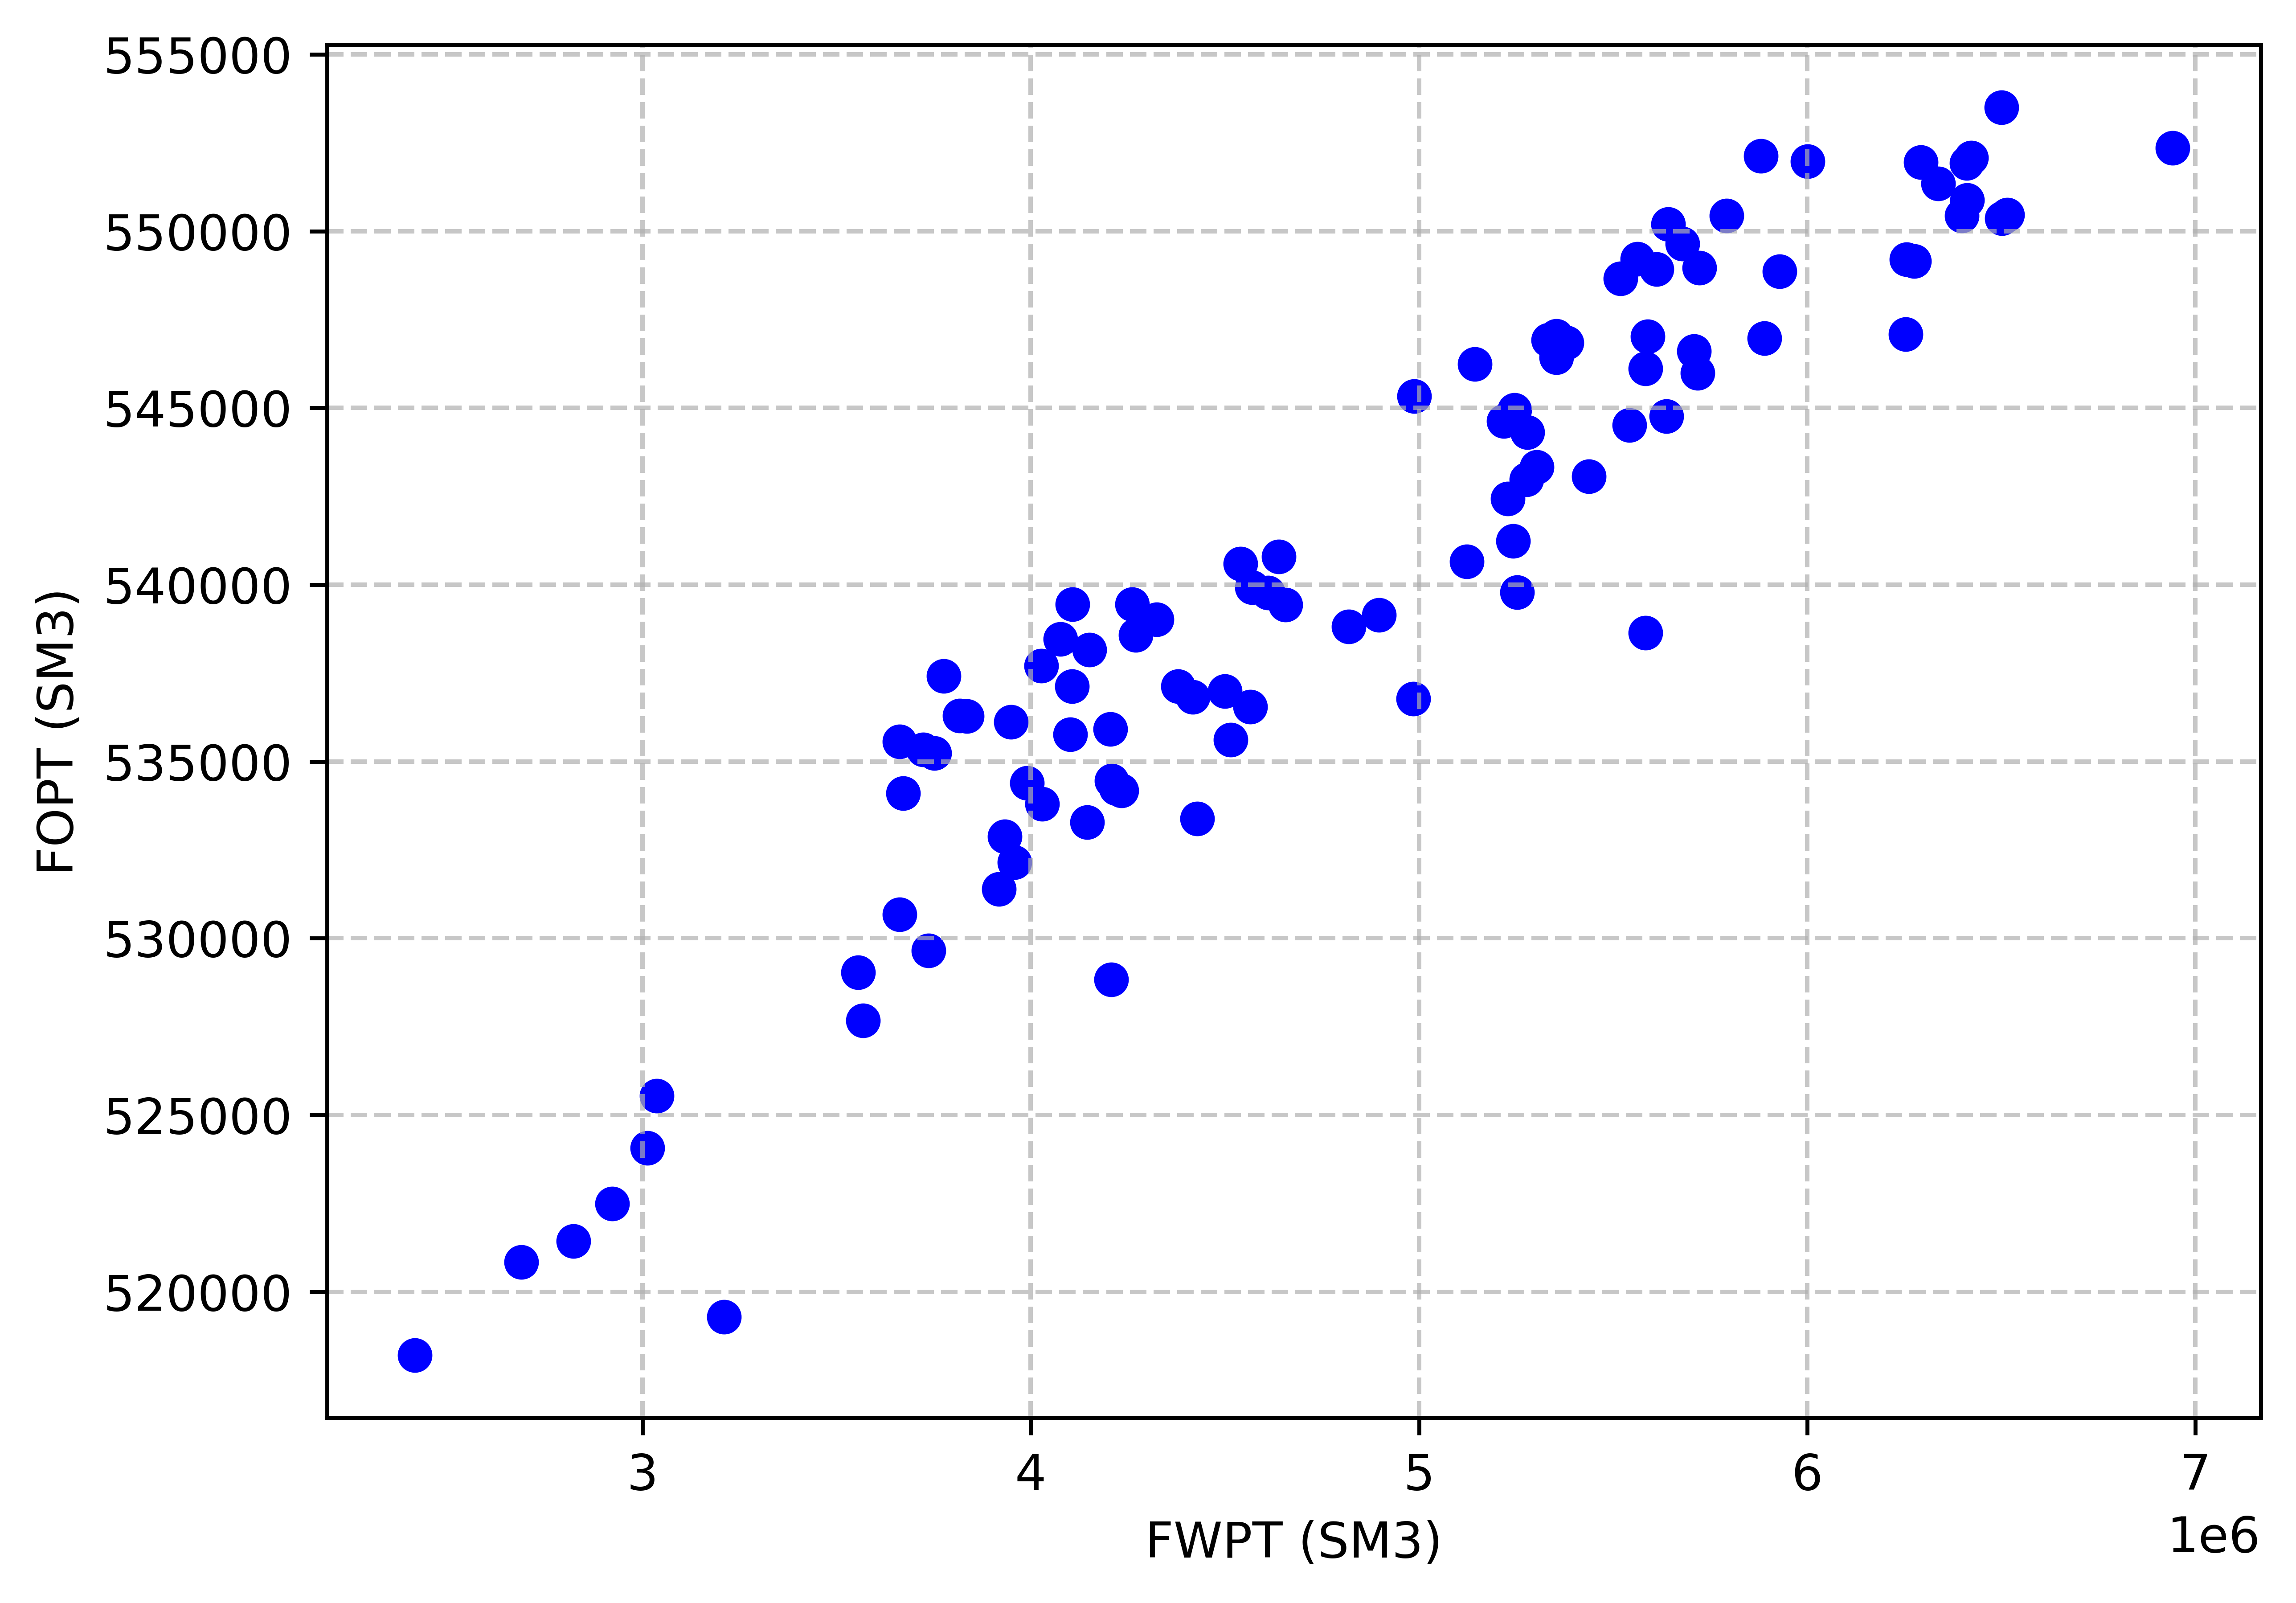

In [8]:
pareto_trials1 = study.best_trials
fopts1 = [t.values[0] for t in study.trials if t.values is not None]
fwpts1 = [t.values[1] for t in study.trials if t.values is not None]

plt.figure(figsize=(7,5),dpi=800)
plt.scatter(fwpts1, fopts1, c='blue')
plt.xlabel("FWPT (SM3)")
plt.ylabel("FOPT (SM3)")
plt.grid(True, which="major", linestyle="--", linewidth=0.9, alpha=0.7)
plt.grid(True, which="minor", linestyle="--", linewidth=0.5, alpha=0.4)
plt.show()

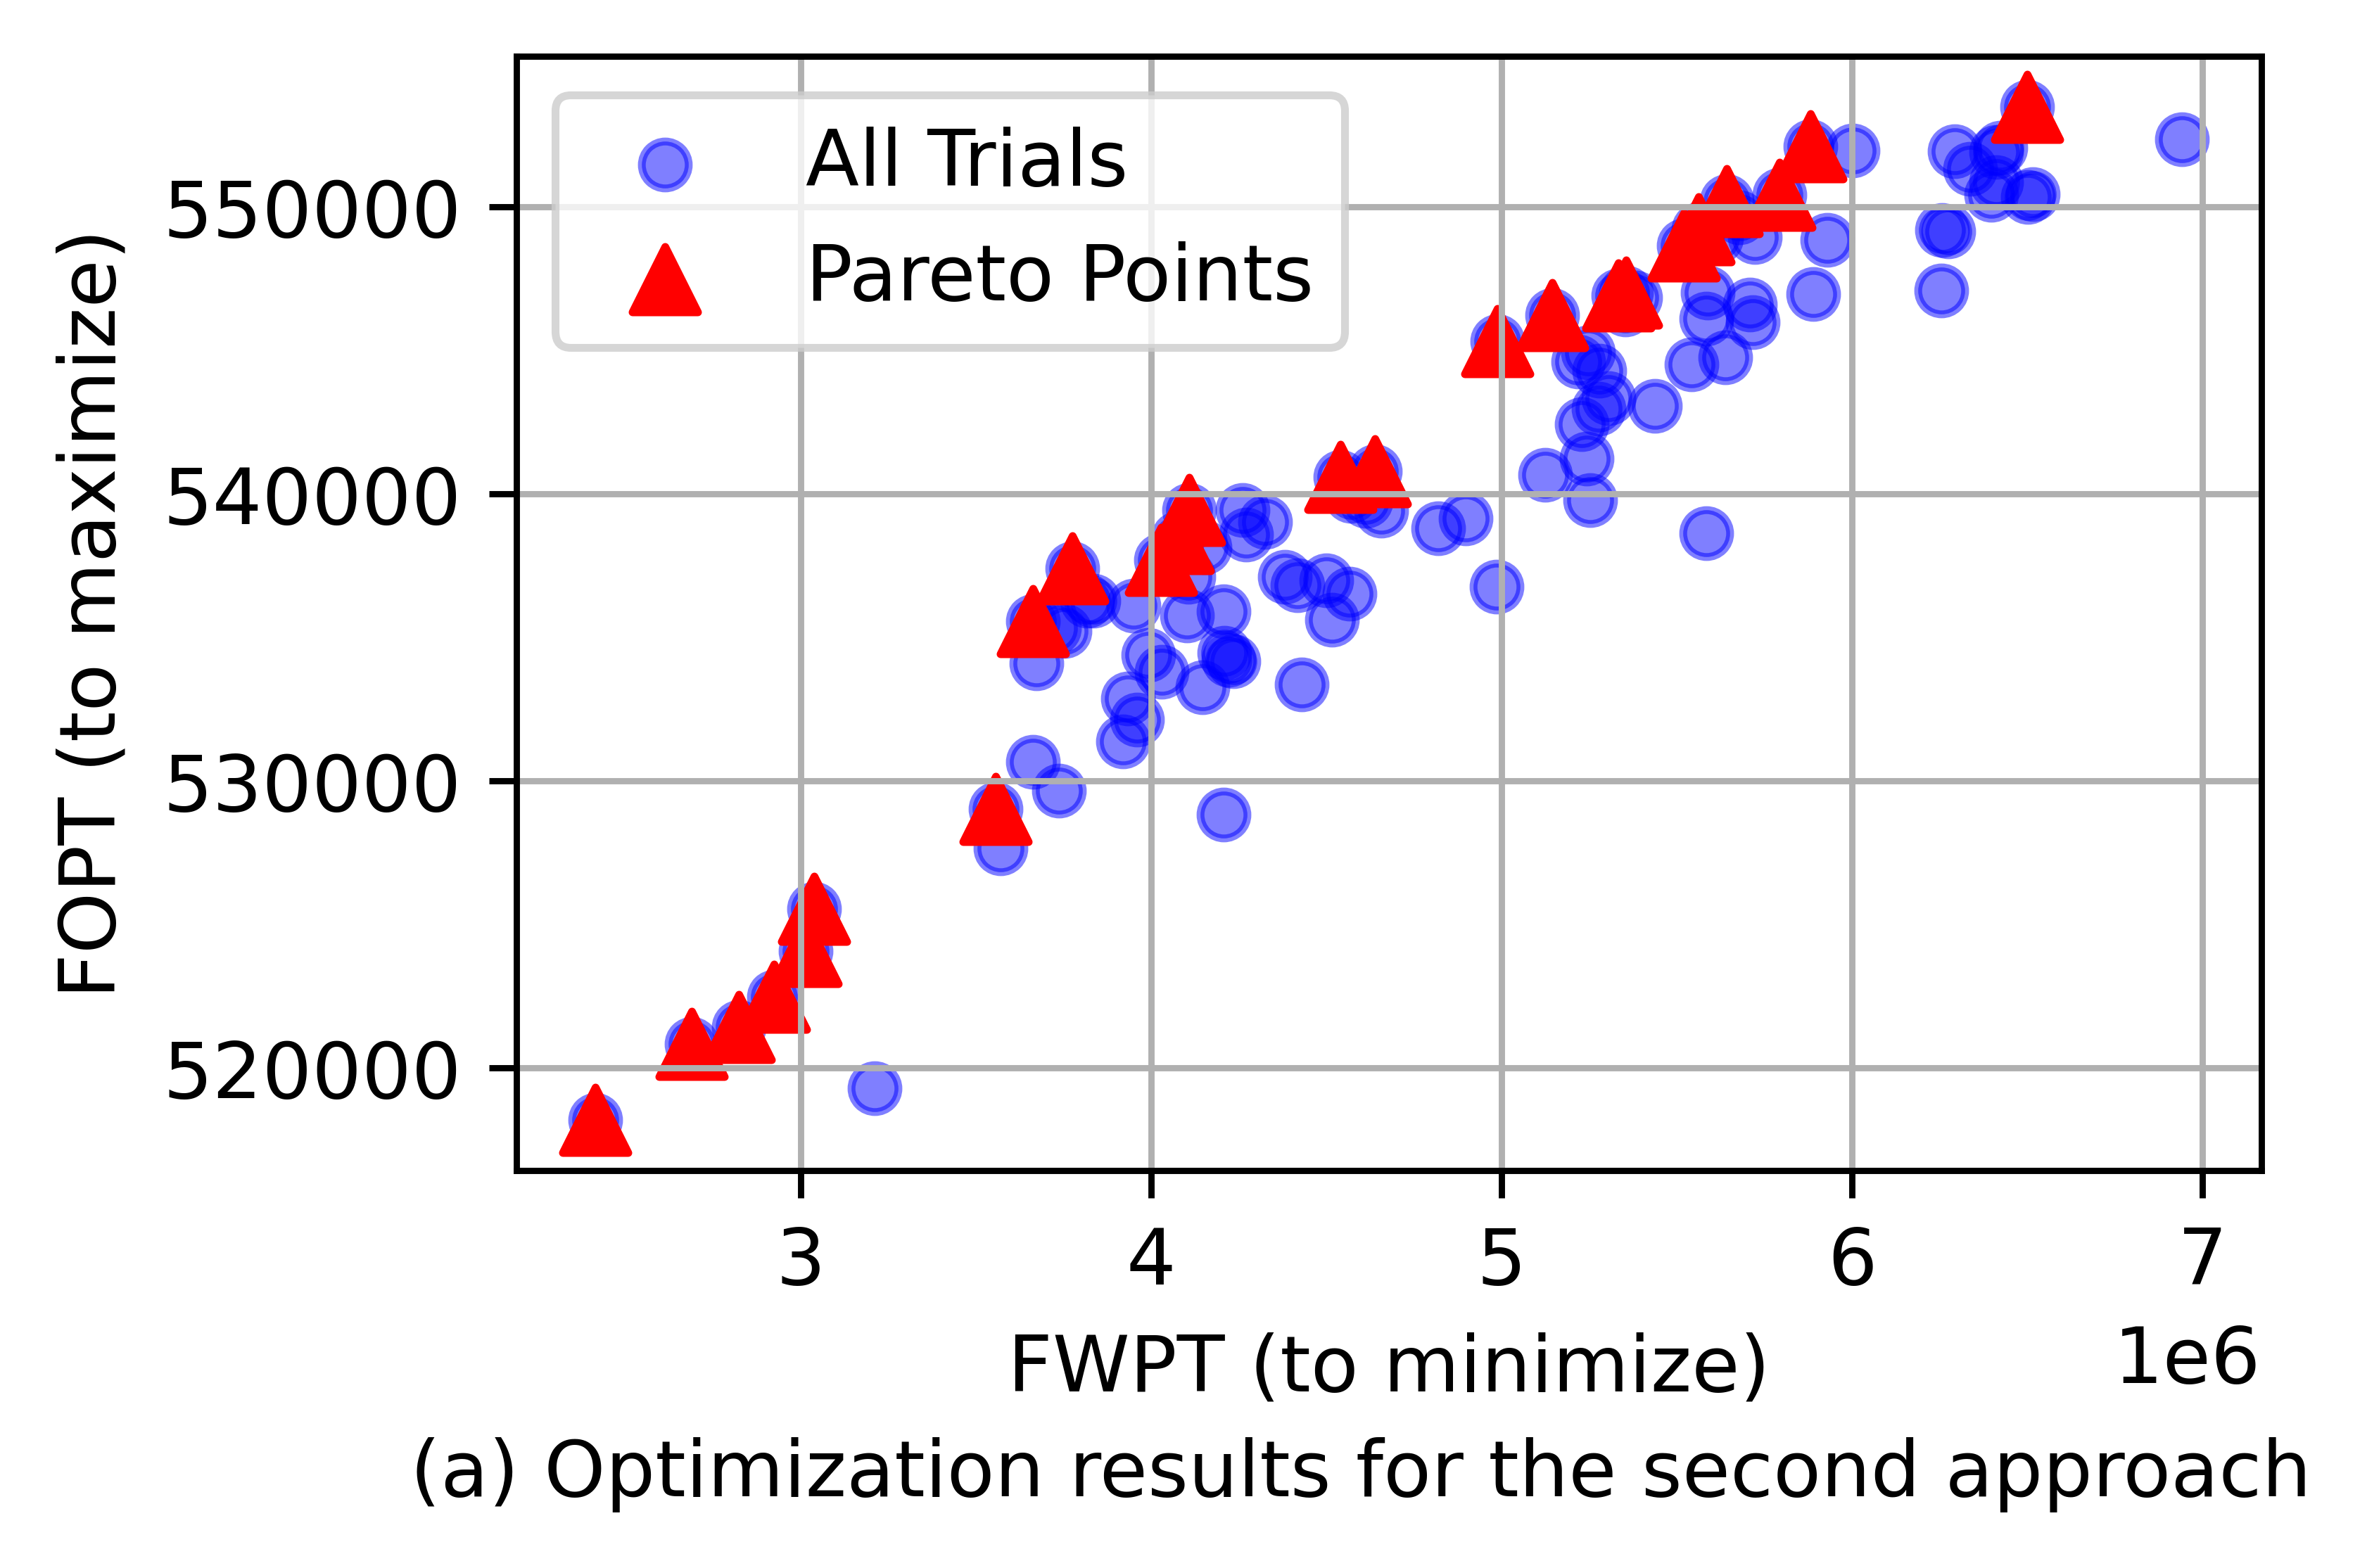

In [9]:
# --- Pareto optimal trials ---
pareto_trials1 = study.best_trials
pareto_fopts = [t.values[0] for t in pareto_trials1]
pareto_fwpts = [t.values[1] for t in pareto_trials1]

# --- Sort Pareto points by FWPT (minimization axis) ---
pareto_points = sorted(zip(pareto_fwpts, pareto_fopts))
pareto_fwpts_sorted, pareto_fopts_sorted = zip(*pareto_points)

# --- All trials ---
fopts = [t.values[0] for t in study.trials if t.values is not None]
fwpts = [t.values[1] for t in study.trials if t.values is not None]

# Create figure
fig, ax = plt.subplots(figsize=(4, 3), dpi=800)

# All solutions
ax.scatter(
    fwpts,
    fopts,
    color='blue',
    alpha=0.5,
    label='All Trials'
)

# Pareto points
ax.scatter(
    pareto_fwpts_sorted,
    pareto_fopts_sorted,
    color='red',
    marker='^',
    s=70,
    label='Pareto Points'
)

# Labels
ax.set_xlabel("FWPT (to minimize)")
ax.set_ylabel("FOPT (to maximize)")

# Legend and grid
ax.legend()
ax.grid(True)

# Leave space for caption
plt.subplots_adjust(bottom=0.22)

# Add caption below the figure
fig.text(
    0.5,
    0.04,
    "(a) Optimization results for the second approach",
    ha="center",
    va="center",
    fontsize=10
)

# Save (optional)
plt.savefig(
    "Optimization_results_second_approach.png",
    dpi=800,
    bbox_inches="tight"
)

plt.show()

# Pareto front optimal results

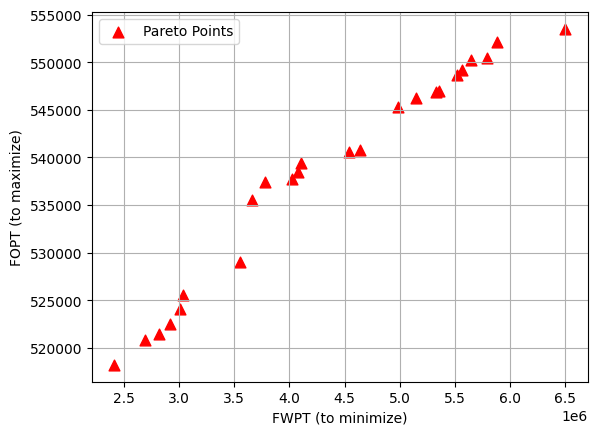

In [10]:
plt.figure()
# Pareto points
plt.scatter(pareto_fwpts_sorted, pareto_fopts_sorted,
            color='red', s=60, label='Pareto Points', marker='^')
plt.xlabel("FWPT (to minimize)")
plt.ylabel("FOPT (to maximize)")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
print("\nPareto Front Table\n")
print("Trial\tFOPT\tFWPT")

for trial in pareto_trials1:
    print(f"{trial.number}\t{trial.values[0]:.2f}\t{trial.values[1]:.2f}")


Pareto Front Table

Trial	FOPT	FWPT
7	540790.10	4639049.00
14	546235.20	5143534.00
17	553501.20	6499790.00
39	540586.20	4540500.00
42	521430.90	2822526.00
43	524072.00	3012906.00
45	538460.70	4076649.00
48	539443.40	4108335.00
49	518207.20	2414009.00
50	529028.90	3556304.00
52	535567.70	3662482.00
55	537706.70	4027268.00
60	525540.80	3036729.00
63	522494.60	2922457.00
64	537408.40	3775632.00
69	545330.40	4987559.00
70	550195.10	5641588.00
72	549217.60	5562407.00
78	546917.10	5333145.00
81	552123.80	5881042.00
83	520833.40	2687768.00
92	548658.30	5518884.00
95	547029.10	5354092.00
97	550434.10	5792358.00


In [16]:
# ===============================
# Constraint definition
# ===============================
FWPT_max = 6200000  # constraint on water production

# Extract Pareto values
fopt = np.array([t.values[0] for t in pareto_trials1])
fwpt = np.array([t.values[1] for t in pareto_trials1])

# ===============================
# Apply constraint (FWPT <= limit)
# ===============================
valid_indices = [i for i, fw in enumerate(fwpt) if fw <= FWPT_max]

if valid_indices:

    # Select best FOPT among valid ones
    best_idx = max(valid_indices, key=lambda i: fopt[i])
    best_trial_constraint = pareto_trials1[best_idx]

    # --- Extract values ---
    best_fopt = best_trial_constraint.values[0]
    best_fwpt = best_trial_constraint.values[1]
    params = best_trial_constraint.params

    # --- Separate BHP and Injection rates ---
    bhp_params = {k: v for k, v in params.items() if "BHP" in k}
    inj_params = {k: v for k, v in params.items() if "inj" in k.lower()}

    # --- Print results ---
    print("========== CONSTRAINED OPTIMAL SOLUTION ==========")
    print(f"Trial Number : {best_trial_constraint.number}")
    print(f"FOPT         : {best_fopt}")
    print(f"FWPT         : {best_fwpt}")

    print("\n--- BHP Parameters ---")
    for k, v in bhp_params.items():
        print(f"{k}: {v}")

    print("\n--- Injection Rate Parameters ---")
    for k, v in inj_params.items():
        print(f"{k}: {v}")

else:
    print("No Pareto solution satisfies the FWPT constraint.")

========== CONSTRAINED OPTIMAL SOLUTION ==========
Trial Number : 81
FOPT         : 552123.8
FWPT         : 5881042.0

--- BHP Parameters ---
BHP1_b1: 192
BHP2_b1: 321
BHP3_b1: 211
BHP4_b1: 201
BHP1_b2: 374
BHP2_b2: 252
BHP3_b2: 232
BHP4_b2: 266
BHP1_b3: 230
BHP2_b3: 378
BHP3_b3: 233
BHP4_b3: 244
BHP1_b4: 268
BHP2_b4: 359
BHP3_b4: 162
BHP4_b4: 179
BHP1_b5: 301
BHP2_b5: 368
BHP3_b5: 164
BHP4_b5: 315

--- Injection Rate Parameters ---
inj_rate1_b1: 311
inj_rate2_b1: 265
inj_rate3_b1: 165
inj_rate4_b1: 63
inj_rate5_b1: 61
inj_rate6_b1: 250
inj_rate7_b1: 368
inj_rate8_b1: 360
inj_rate1_b2: 218
inj_rate2_b2: 330
inj_rate3_b2: 397
inj_rate4_b2: 59
inj_rate5_b2: 390
inj_rate6_b2: 220
inj_rate7_b2: 206
inj_rate8_b2: 196
inj_rate1_b3: 292
inj_rate2_b3: 319
inj_rate3_b3: 370
inj_rate4_b3: 124
inj_rate5_b3: 314
inj_rate6_b3: 184
inj_rate7_b3: 174
inj_rate8_b3: 110
inj_rate1_b4: 221
inj_rate2_b4: 295
inj_rate3_b4: 248
inj_rate4_b4: 97
inj_rate5_b4: 94
inj_rate6_b4: 91
inj_rate7_b4: 77
inj_rate8_b4

# Sensitivity analysis of interval effect on optimization results

In [24]:
pareto_numbers = {t.number for t in study.best_trials}

df = pd.DataFrame([
    {
        "Trial": t.number,
        "FOPT": t.values[0],
        "FWPT": t.values[1],
        "Pareto": t.number in pareto_numbers
    }
    for t in study.trials
    if t.values is not None
])

df.to_csv("results_2years.csv", index=False)

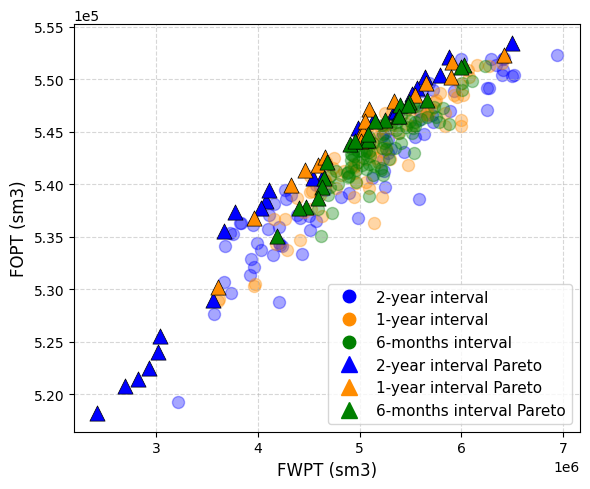

In [34]:
files = {
    "2-year interval": "results_2years.csv",
    "1-year interval": "results_1year.csv",
    "6-month interval": "results_6months.csv"
}

colors = {
    "2-year interval": "blue",
    "1-year interval": "darkorange",
    "6-month interval": "green"
}

fig, ax = plt.subplots(figsize=(6, 5))

for label, filename in files.items():

    df = pd.read_csv(filename)
    color = colors[label]

    # Non-Pareto solutions
    non_pareto = df[~df["Pareto"]]

    ax.scatter(
        non_pareto["FWPT"],
        non_pareto["FOPT"],
        s=75,
        marker="o",
        color=color,
        alpha=0.35
    )

    # Pareto-optimal solutions
    pareto = df[df["Pareto"]]

    ax.scatter(
        pareto["FWPT"],
        pareto["FOPT"],
        s=120,
        marker="^",
        color=color,
        edgecolors="black",
        linewidths=0.5,
        zorder=5
    )

# Legend
legend = [
    Line2D([], [], marker="o", linestyle="None",
           color="blue", markersize=9,
           label="2-year interval"),

    Line2D([], [], marker="o", linestyle="None",
           color="darkorange", markersize=9,
           label="1-year interval"),

    Line2D([], [], marker="o", linestyle="None",
           color="green", markersize=9,
           label="6-months interval"),

    Line2D([], [], marker="^", linestyle="None",
           color="blue", markersize=11,
           label="2-year interval Pareto"),

    Line2D([], [], marker="^", linestyle="None",
           color="darkorange", markersize=11,
           label="1-year interval Pareto"),

    Line2D([], [], marker="^", linestyle="None",
           color="green", markersize=11,
           label="6-months interval Pareto")
]

ax.set_xlabel("FWPT (sm3)", fontsize=12)
ax.set_ylabel("FOPT (sm3)", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.5)
ax.ticklabel_format(axis="both", style="sci", scilimits=(0, 0))
ax.legend(handles=legend, fontsize=11)

plt.tight_layout()
plt.savefig("Comparison_Control_Intervals.png",
            dpi=300, bbox_inches="tight")
plt.show()
